# 04 一室の発熱と蓄熱

外気5℃、100 m³/h換気、壁50 W/K、内部発熱500 Wの一室。

## 到達目標
C dT/dt = H(Tout−T)+ρcp Q(Tout−T)+q。thermal_massはJ/K、vはm³であり両者を区別する。

## 実行環境
Python 3.10以上とvtsimnx engineが必要です。Colabのlocalhostは手元PCのサーバーを指しません。次の設定セルのAPI URLを到達可能なものに変更します。APIキーは環境変数で渡し、ノートに保存しません。

検証engine commit: `5eeffb2f8012a2fe41bca705450b0dd0a952326d`。入力モデルは実計算確認済ですが、原住宅の年間再現とは範囲が異なります。

## 実行版の使い方
このノートは検証対象のvtsimnx commit 5eeffb2f8012a2fe41bca705450b0dd0a952326d に合わせた代表教材です。上から順に実行します。
Pythonクライアントの導入だけではengineは起動しません。教材17以外は接続可能なengineと、必要に応じてVTSIMNX_API_KEYが必要です。Colabの127.0.0.1は手元PCのengineを指しません。
入力はノート内に含めています。元のDriveパスや測定CSVを別途読む必要はありません。
出力は教材フォルダ内のresults/04/に保存します。詳しい準備は同じフォルダの00_実行ガイド.ipynbを参照してください。


In [1]:
import os, sys, subprocess
# 検証runnerのみ専用環境で導入済みの依存を再利用する。通常はこのセルで導入する。
if os.environ.get("VTSIMNX_TUTORIAL_SKIP_INSTALL") != "1":
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade", "pip", "setuptools>=68,<81", "wheel"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
        "vtsimnx @ git+https://github.com/iguchi-lab/vtsimnx@5eeffb2f8012a2fe41bca705450b0dd0a952326d",
        "matplotlib", "japanize-matplotlib"])


In [2]:
import os, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import japanize_matplotlib
from IPython.display import display
import vtsimnx as vt

# ローカルJupyterでは、ノートブックと同じフォルダを作業フォルダにする。
DATA_DIR = Path(os.environ.get("VTSIMNX_TUTORIAL_DATA", ".")).expanduser().resolve()
BASE_URL = os.environ.get("VTSIMNX_API_URL", "http://127.0.0.1:8000")
API_KEY = os.environ.get("VTSIMNX_API_KEY")
OUTPUT = DATA_DIR / "results" / "04"
OUTPUT.mkdir(parents=True, exist_ok=True)


## 入力を読む
次の辞書はvtsimnxのネイティブ形式です。風量はm³/s、熱量はW、熱容量はJ/Kです。

In [3]:
configs = {'04_room_heat': {'builder': {},
                  'simulation': {'index': {'start': '2026-01-01T00:00:00',
                                           'end': '2026-01-01T23:00:00',
                                           'length': 24,
                                           'timestep': 3600}},
                  'nodes': [{'key': 'outside', 't': 5},
                            {'key': 'room', 'calc_t': True, 't': 20, 'v': 100, 'thermal_mass': 120720}],
                  'ventilation_branches': [{'key': 'outside->room',
                                            'source': 'outside',
                                            'target': 'room',
                                            'vol': 0.027777777777777776},
                                           {'key': 'room->outside',
                                            'source': 'room',
                                            'target': 'outside',
                                            'vol': 0.027777777777777776}],
                  'thermal_branches': [{'key': 'outside->room',
                                        'source': 'outside',
                                        'target': 'room',
                                        'conductance': 50}],
                  'heat_source': [{'key': 'internal',
                                   'room': 'room',
                                   'generation_rate': 500,
                                   'convection': 1,
                                   'radiation': 0}]}}


## 実行と結果の取得
計算ごとの要求JSONを保存し、必要な系列をDataFrameとして取得します。

In [4]:
results = {}
for name, config in configs.items():
    results[name] = vt.run_calc(BASE_URL, config, api_key=API_KEY,
        as_result=True, raise_on_error=True, timeout=1800, request_output_path=OUTPUT / (name + "_request.json"))
    print(name, results[name].artifact_dir)


04_room_heat artifacts.1794699390694.output.d25cdd95aea74460b473f95a7ea8c6a1


04_room_heat


,outside,room,void
time,,,
2026-01-01 00:00:00,5.0,13.567768,20.0
2026-01-01 01:00:00,5.0,11.725277,20.0
2026-01-01 02:00:00,5.0,11.197502,20.0
2026-01-01 03:00:00,5.0,11.046324,20.0
2026-01-01 04:00:00,5.0,11.003018,20.0


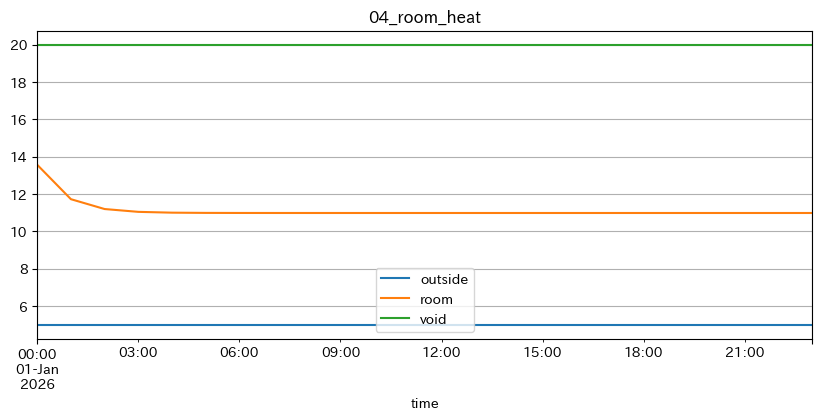

In [5]:
frames = {name: result.get_series_df('thermal_temperature', raise_on_error=True) for name, result in results.items()}
for name, frame in frames.items():
    print(name)
    display(frame.head())
    frame.to_csv(OUTPUT / (name + "_thermal_temperature.csv"), encoding="utf-8-sig")
    frame.plot(title=name, figsize=(10, 4), grid=True)


## 確認・発展
熱容量を10倍にし、定常値と立ち上がり時間を比べる。

保存された時刻の値は当該ステップ更新後の値です。初期値との比較ではこの差に注意します。

## 原典との対応
- S013 三木　シュミレーション のコピー
- S014 三木　シュミレーション のコピー
- S015 東大阪地点　いちと のコピー
- S029 240630_higashiosaka.ipynb
- S030 250111_東大阪2024_data整理.ipynb
- S031 250111_東大阪2024分析_r2.ipynb
- S032 250111_東大阪2024分析_r2.ipynb のコピー
- S033 250114_東大阪2024分析_r2.ipynb
- S039 東大阪地点　いちと のコピー
- S043 220225_東大阪.ipynb
- S044 220228_東大阪.ipynb
- S045 220301_1700_東大阪calc.ipynb

S番号は原典調査時の識別子です。原典の完全な台帳は管理者のDrive整理資料に保管しています。